In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Goal: Analyze a technology store's sales data, uncover useful business insights, visualize performance, and present recommendations as if a store manager had asked me to investigate the business.

# Investigation

In [16]:
df = pd.read_csv("tech_store_sales_practice.csv")
print(df.describe())
print(df.head())
print(df.shape)


       Units_Sold  Unit_Price_USD   Revenue_USD  Ad_Spend_USD  \
count  150.000000      150.000000    150.000000    150.000000   
mean     7.400000      274.266667   2020.066667    267.407800   
std      4.091241      290.355826   2437.901919    133.784185   
min      1.000000       50.000000     50.000000     50.350000   
25%      4.000000       90.000000    500.000000    152.445000   
50%      7.500000      120.000000   1200.000000    267.105000   
75%     11.000000      300.000000   2650.000000    394.807500   
max     14.000000     1200.000000  15600.000000    494.100000   

       Customer_Rating  Returned_Units  
count       150.000000      150.000000  
mean          4.259800        0.120000  
std           0.428609        0.432256  
min           3.500000        0.000000  
25%           3.880000        0.000000  
50%           4.295000        0.000000  
75%           4.610000        0.000000  
max           4.990000        2.000000  
         Date     Category                   

# Data Quality

Checking whether there is any missing or duplicated rows and investigate whether Date is a datetime column.

In [17]:
df.isnull().sum()
df.isnull().values.any()

df.columns[df.columns.duplicated()].to_list()
df["Date"] = pd.to_datetime(df["Date"])


# Validating the Data

Checking for impossible or suspicious values in Units_Sold, Unit_Price_USD, Revenue_USD, Ad_Spend_USD, Customer_Rating, and Returned_Units.

In [18]:
print((df["Returned_Units"] > df["Units_Sold"]).sum())
print((df["Revenue_USD"] != df["Units_Sold"] * df["Unit_Price_USD"]).sum())

0
0


# EDA (Exploratory Data Analysis)

Goal: Calculate total revenue, total units sold, total advertising spend, total returned units, and average customer rating.

In [19]:
calculate = df.groupby("Product").agg({
    "Revenue_USD": "sum",
    "Units_Sold": "sum",
    "Ad_Spend_USD":"sum",
    "Returned_Units": "sum",
    "Customer_Rating": "mean"
})

print(calculate)


                            Revenue_USD  Units_Sold  Ad_Spend_USD  \
Product                                                             
Bluetooth Speaker                  7920          88       3730.20   
Fitness Band                      15800         158       6680.72   
Laptop Pro                        79200          66       2153.61   
Mechanical Keyboard               15600         130       2925.87   
Noise-Canceling Headphones        37750         151       6822.28   
Smart Monitor                     61200         136       4251.50   
Smartwatch Series X               45300         151       4282.34   
Tablet Air                        28800          48       1974.70   
USB-C Dock                         6240          78       3083.35   
Wireless Mouse                     5200         104       4206.60   

                            Returned_Units  Customer_Rating  
Product                                                      
Bluetooth Speaker                        4     

# Product Summary

In [20]:
total_reveneu = df["Revenue_USD"].sum()
total_units = df["Units_Sold"].sum()
total_ad_Spend = df["Ad_Spend_USD"].sum()
total_returned_Unit = df["Returned_Units"].sum()
customer_rating = df["Customer_Rating"].mean()

print(f"Total Revenue: {total_reveneu}")
print(f"Total Units Sold: {total_units}")
print(f"Total Ad Spend: {total_ad_Spend}")
print(f"Total Returned Unit: {total_returned_Unit}")
print(f"Average Customer Rating: {customer_rating:.2f}")


Total Revenue: 303010
Total Units Sold: 1110
Total Ad Spend: 40111.17
Total Returned Unit: 18
Average Customer Rating: 4.26


# Revenue By Product

Goal: Find the top five products by total revenue

In [21]:
top_product = df.groupby("Product")["Revenue_USD"].sum().reset_index()
top_product = top_product.sort_values(by="Revenue_USD", ascending=False).head(5)
print(top_product)


                      Product  Revenue_USD
2                  Laptop Pro        79200
5               Smart Monitor        61200
6         Smartwatch Series X        45300
4  Noise-Canceling Headphones        37750
7                  Tablet Air        28800


# Revenue By Category

Goal: Compare total revenue across categories.

In [22]:
total_revenue = df.groupby("Category")["Revenue_USD"].sum().reset_index()
print(total_revenue)


      Category  Revenue_USD
0  Accessories        27040
1        Audio        45670
2  Electronics       169200
3    Wearables        61100


# Revenue By Region

Goal: Compare total revenue across regions.

In [23]:
region = df.groupby("Region")["Revenue_USD"].sum()
print(region)


Region
East     66440
North    56640
South    95970
West     83960
Name: Revenue_USD, dtype: int64


# Average Customer Rating

Goal: Identify which product has the highest average customer rating

In [24]:
rating = df.groupby("Product")["Customer_Rating"].mean()
sorted = rating.sort_values(ascending=False)
print(sorted)

Product
Tablet Air                    4.530000
Laptop Pro                    4.400000
Noise-Canceling Headphones    4.385909
USB-C Dock                    4.375833
Smartwatch Series X           4.291875
Fitness Band                  4.220000
Bluetooth Speaker             4.158333
Wireless Mouse                4.154000
Smart Monitor                 4.152941
Mechanical Keyboard           4.100000
Name: Customer_Rating, dtype: float64


# Data Visualization

Product Performance

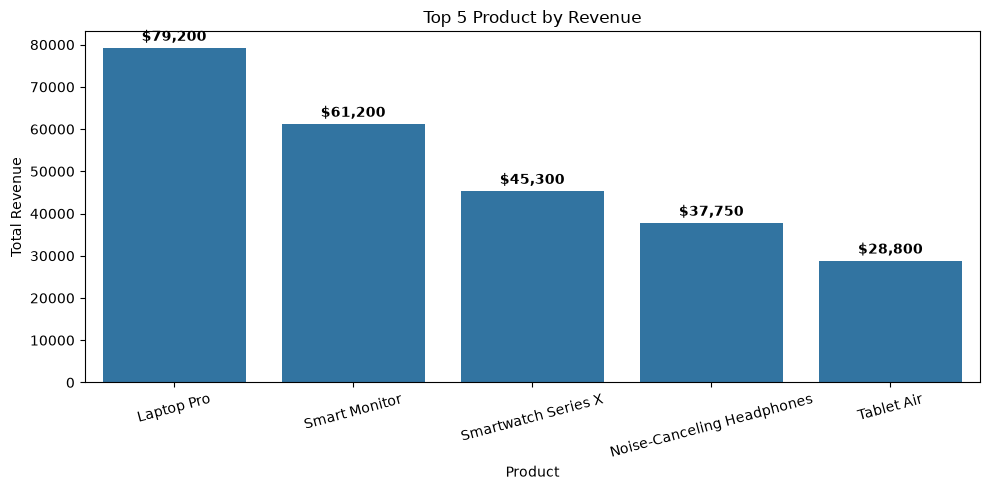

In [34]:
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=top_product,
    x="Product",
    y="Revenue_USD"
)

for p in ax.patches:
    ax.annotate(
        f"${p.get_height():,.0f}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 8),
        textcoords="offset points",
        fontweight="bold",
    )

plt.title("Top 5 Product by Revenue")
plt.xlabel("Product")
plt.ylabel("Total Revenue")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Category and Regional Revenue


Goal: Compare how categories and regions perform

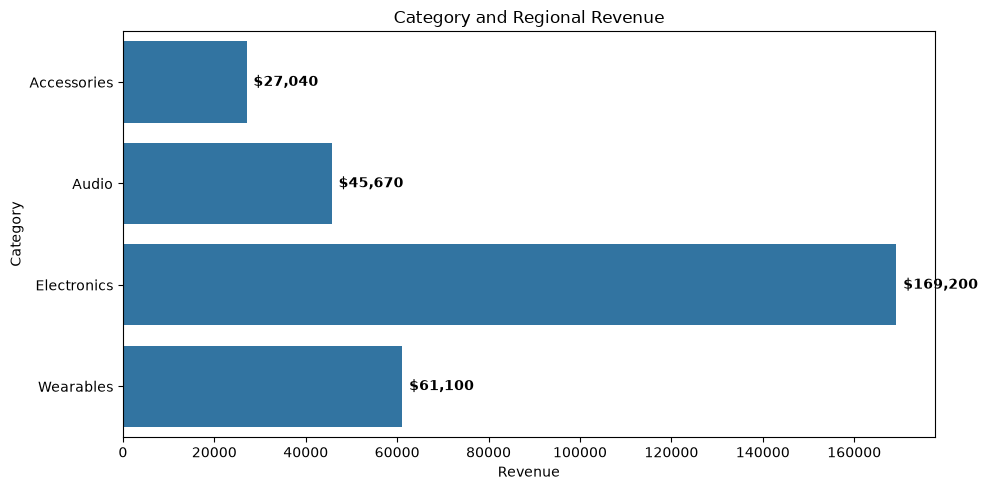

In [ ]:
plt.figure(figsize=(10, 5))
ab = sns.barplot(
    data=total_revenue,
    x="Revenue_USD",
    y="Category",
)

for i in ab.patches:
    width = i.get_width()  
    ab.annotate(
        f"${width:,.0f}",  
        (width, i.get_y() + i.get_height() / 2.0),
        ha="left",
        va="center",
        xytext=(5, 0),
        textcoords="offset points",
        fontweight="bold",
    )

plt.title("Total Revenue by Category")
plt.xlabel("Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()